In [1]:
!pip install xlrd openpyxl -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

Saving sample_-_superstore.xls to sample_-_superstore.xls


In [3]:
file_name = next(iter(uploaded))

df = pd.read_excel(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (10194, 21)


In [4]:
# Display the first 5 rows
display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [5]:
# Check dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# View column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

Rows: 10194
Columns: 21

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-nul

In [6]:
# Statistical summary of numerical columns
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
Row ID,10194.0,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
Order Date,10194,2025-04-29 11:48:25.002942720,2023-01-03 00:00:00,2024-05-14 00:00:00,2025-06-25 00:00:00,2026-05-14 00:00:00,2026-12-30 00:00:00,NaN
Ship Date,10194,2025-05-03 10:52:45.626839296,2023-01-07 00:00:00,2024-05-19 00:00:00,2025-06-28 00:00:00,2026-05-18 00:00:00,2027-01-05 00:00:00,NaN
Sales,10194.0,228.225854,0.444,17.22,53.91,209.5,22638.48,619.906839
Quantity,10194.0,3.791838,1.0,2.0,3.0,5.0,14.0,2.228317
Discount,10194.0,0.155385,0.0,0.0,0.2,0.2,0.8,0.206249
Profit,10194.0,28.673417,-6599.978,1.7608,8.69,29.297925,8399.976,232.465115


In [7]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
display(missing_values[missing_values > 0])

print("Total missing values:", df.isnull().sum().sum())

Missing values by column:


,0


Total missing values: 0


In [8]:
# Count fully duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [9]:
# Review each column's data type
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values
}))

,Column,Data Type,Unique Values
0,Row ID,int64,10194
1,Order ID,object,5111
2,Order Date,datetime64[ns],1242
3,Ship Date,datetime64[ns],1338
4,Ship Mode,object,4
5,Customer ID,object,804
6,Customer Name,object,800
7,Segment,object,3
8,Country/Region,object,2
9,City,object,542


In [10]:
date_columns = ["Order Date", "Ship Date"]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print(df[date_columns].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [11]:
print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())

Invalid Order Dates: 0
Invalid Ship Dates: 0


In [12]:
numeric_columns = ["Sales", "Quantity", "Discount", "Profit"]

display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Sales,10194.0,228.225854,619.906839,0.444,17.2200,53.91,209.500000,22638.480
Quantity,10194.0,3.791838,2.228317,1.000,2.0000,3.00,5.000000,14.000
Discount,10194.0,0.155385,0.206249,0.000,0.0000,0.20,0.200000,0.800
Profit,10194.0,28.673417,232.465115,-6599.978,1.7608,8.69,29.297925,8399.976


In [13]:
print("FINAL DATA QUALITY SUMMARY")
print("-" * 35)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Invalid order dates:", df["Order Date"].isna().sum())
print("Invalid ship dates:", df["Ship Date"].isna().sum())

FINAL DATA QUALITY SUMMARY
-----------------------------------
Rows: 10194
Columns: 21
Missing values: 0
Duplicate rows: 0
Invalid order dates: 0
Invalid ship dates: 0


In [14]:
# Overall business KPIs

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()
total_quantity = df["Quantity"].sum()
profit_margin = (total_profit / total_sales) * 100

print("SUPERSTORE BUSINESS OVERVIEW")
print("-" * 40)
print(f"Total Sales:       ${total_sales:,.2f}")
print(f"Total Profit:      ${total_profit:,.2f}")
print(f"Total Orders:      {total_orders:,}")
print(f"Unique Customers:  {total_customers:,}")
print(f"Unique Products:   {total_products:,}")
print(f"Units Sold:        {total_quantity:,}")
print(f"Profit Margin:     {profit_margin:.2f}%")

SUPERSTORE BUSINESS OVERVIEW
----------------------------------------
Total Sales:       $2,326,534.35
Total Profit:      $292,296.81
Total Orders:      5,111
Unique Customers:  804
Unique Products:   1,862
Units Sold:        38,654
Profit Margin:     12.56%


In [15]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Order_Count=("Order ID", "nunique")
).sort_values("Total_Sales", ascending=False)

category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"] * 100
)

display(category_analysis.round(2))

,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
Category,,,,,
Technology,839893.28,146543.38,7017,1560,17.45
Furniture,754747.76,19730.00,8369,1819,2.61
Office Supplies,731893.31,126023.44,23268,3812,17.22


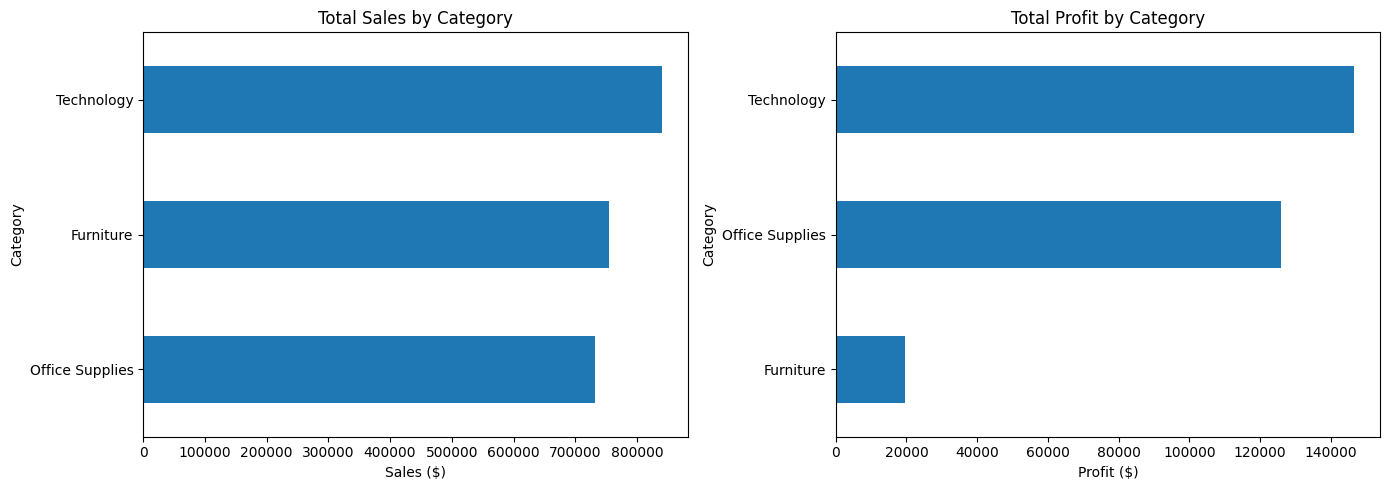

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales by category
category_analysis["Total_Sales"].sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Total Sales by Category")
axes[0].set_xlabel("Sales ($)")
axes[0].set_ylabel("Category")

# Profit by category
category_analysis["Total_Profit"].sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Total Profit by Category")
axes[1].set_xlabel("Profit ($)")
axes[1].set_ylabel("Category")

plt.tight_layout()
plt.show()

In [17]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Order_Count=("Order ID", "nunique")
)

region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"] * 100
)

region_analysis = region_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(region_analysis.round(2))

,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
Region,,,,,
West,739813.61,110798.82,12466,1635,14.98
East,691828.17,94883.26,11159,1475,13.71
Central,503170.67,39865.31,8820,1179,7.92
South,391721.90,46749.43,6209,822,11.93


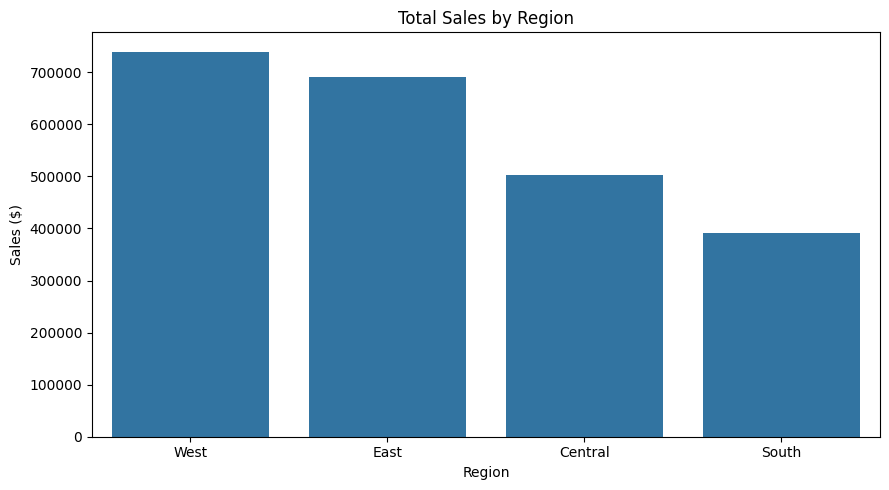

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Total_Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

In [19]:
# Extract the month from Order Date
df["Order Month"] = (
    df["Order Date"].dt.to_period("M").dt.to_timestamp()
)

# Aggregate sales and profit by month
monthly_analysis = df.groupby("Order Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

display(monthly_analysis.head(10))

,Order Month,Total_Sales,Total_Profit,Total_Orders
0,2023-01-01,14518.0550,2539.3907,33
1,2023-02-01,4519.8920,862.3084,28
2,2023-03-01,56933.9090,693.4499,72
3,2023-04-01,28295.3450,3488.8352,66
4,2023-05-01,26319.7670,3196.3918,72
5,2023-06-01,34669.4796,4999.7594,67
6,2023-07-01,33946.3930,-841.4826,65
7,2023-08-01,28918.3385,5765.2250,75
8,2023-09-01,82670.4288,8593.6302,134
9,2023-10-01,32413.3390,3469.1749,81


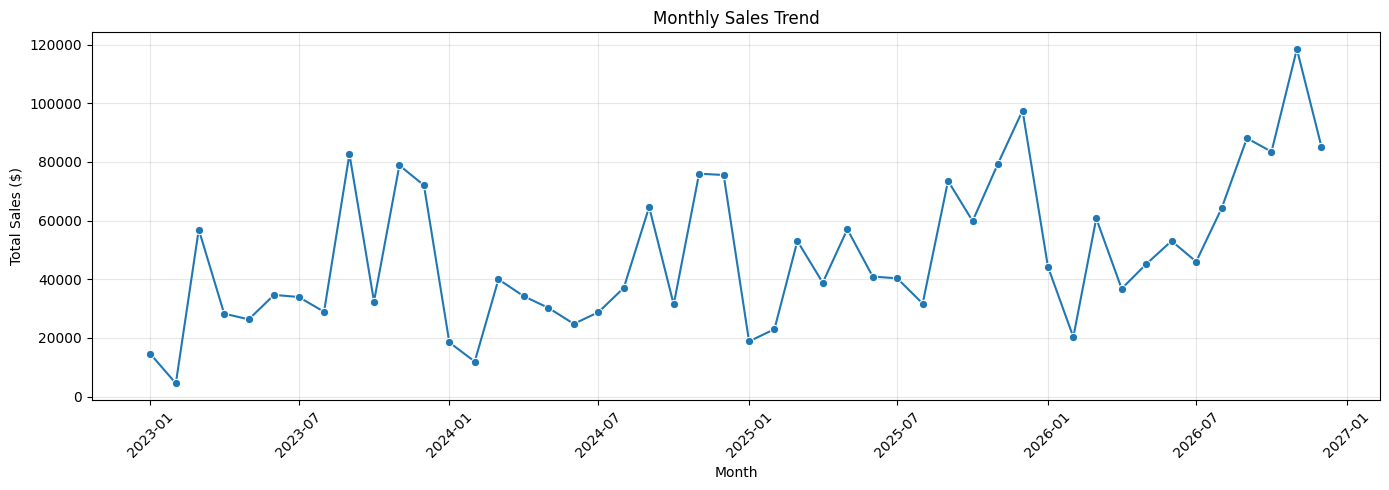

In [20]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Order Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

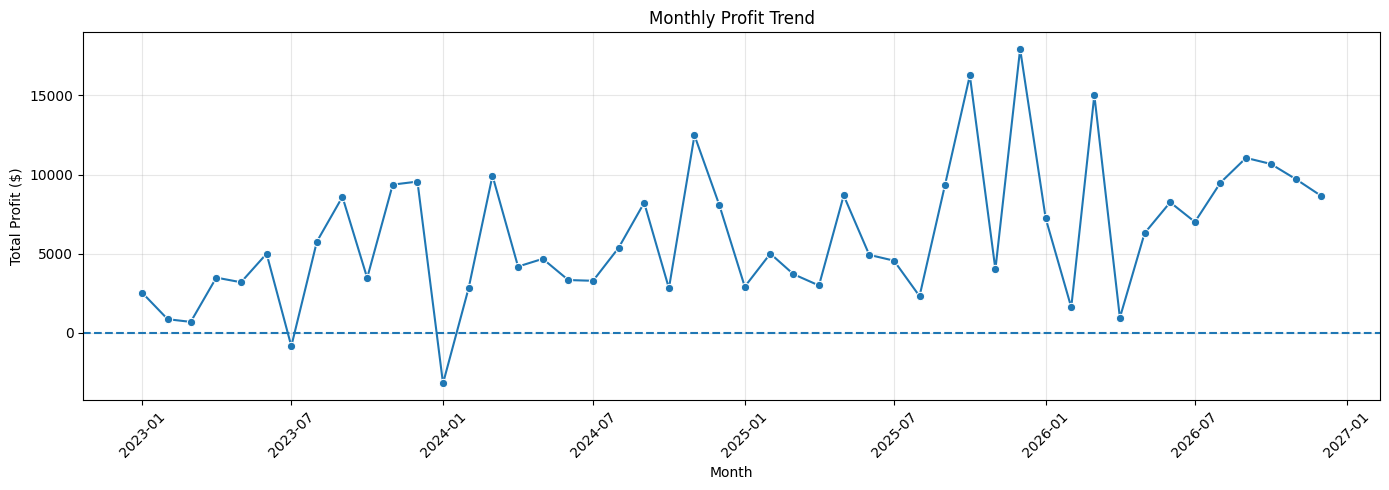

In [21]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Order Month",
    y="Total_Profit",
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
best_sales_month = monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmax()
]

worst_sales_month = monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmin()
]

best_profit_month = monthly_analysis.loc[
    monthly_analysis["Total_Profit"].idxmax()
]

worst_profit_month = monthly_analysis.loc[
    monthly_analysis["Total_Profit"].idxmin()
]

print("BEST SALES MONTH")
print(best_sales_month.to_string())

print("\nLOWEST SALES MONTH")
print(worst_sales_month.to_string())

print("\nHIGHEST PROFIT MONTH")
print(best_profit_month.to_string())

print("\nLOWEST PROFIT MONTH")
print(worst_profit_month.to_string())

BEST SALES MONTH
Order Month     2026-11-01 00:00:00
Total_Sales              118454.505
Total_Profit              9692.1037
Total_Orders                    262

LOWEST SALES MONTH
Order Month     2023-02-01 00:00:00
Total_Sales                4519.892
Total_Profit               862.3084
Total_Orders                     28

HIGHEST PROFIT MONTH
Order Month     2025-12-01 00:00:00
Total_Sales               97502.277
Total_Profit             17926.3013
Total_Orders                    185

LOWEST PROFIT MONTH
Order Month     2024-01-01 00:00:00
Total_Sales              18461.9156
Total_Profit              -3189.803
Total_Orders                     31


In [23]:
df["Order Year"] = df["Order Date"].dt.year

yearly_analysis = df.groupby("Order Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

yearly_analysis["Profit_Margin_%"] = (
    yearly_analysis["Total_Profit"] /
    yearly_analysis["Total_Sales"] * 100
)

display(yearly_analysis.round(2))

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
Order Year,,,,
2023,494040.21,51684.30,995,10.46
2024,472993.03,62020.97,1053,13.11
2025,613933.58,82665.20,1340,13.46
2026,745567.53,95926.35,1723,12.87


In [24]:
print("First order date:", df["Order Date"].min())
print("Last order date:", df["Order Date"].max())

print("\nOrders by year:")
display(df.groupby("Order Year").size().rename("Rows").to_frame())

First order date: 2023-01-03 00:00:00
Last order date: 2026-12-30 00:00:00

Orders by year:


,Rows
Order Year,
2023,2051
2024,2130
2025,2634
2026,3379


In [25]:
subcategory_analysis = df.groupby(
    ["Category", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Order_Count=("Order ID", "nunique")
).reset_index()

subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"] * 100
)

# Sort by profit, highest first
subcategory_analysis = subcategory_analysis.sort_values(
    "Total_Profit", ascending=False
)

display(subcategory_analysis.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
14,Technology,Copiers,150745.29,56093.94,242,70,37.21
16,Technology,Phones,331842.64,45050.83,3357,826,13.58
13,Technology,Accessories,167380.32,41936.64,2976,718,25.05
10,Office Supplies,Paper,79540.54,34511.51,5207,1205,43.39
6,Office Supplies,Binders,207354.88,31426.10,6071,1339,15.16
1,Furniture,Chairs,335768.25,27223.53,2431,591,8.11
11,Office Supplies,Storage,224644.55,21285.11,3191,787,9.48
4,Office Supplies,Appliances,108213.18,18329.48,1750,459,16.94
2,Furniture,Furnishings,95598.13,13891.74,3799,919,14.53
7,Office Supplies,Envelopes,16528.36,6988.02,914,251,42.28


In [26]:
top_5_subcategories = subcategory_analysis.nlargest(
    5, "Total_Profit"
)

bottom_5_subcategories = subcategory_analysis.nsmallest(
    5, "Total_Profit"
)

print("TOP 5 SUB-CATEGORIES BY PROFIT")
display(top_5_subcategories.round(2))

print("BOTTOM 5 SUB-CATEGORIES BY PROFIT")
display(bottom_5_subcategories.round(2))

TOP 5 SUB-CATEGORIES BY PROFIT


,Category,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
14,Technology,Copiers,150745.29,56093.94,242,70,37.21
16,Technology,Phones,331842.64,45050.83,3357,826,13.58
13,Technology,Accessories,167380.32,41936.64,2976,718,25.05
10,Office Supplies,Paper,79540.54,34511.51,5207,1205,43.39
6,Office Supplies,Binders,207354.88,31426.10,6071,1339,15.16


BOTTOM 5 SUB-CATEGORIES BY PROFIT


,Category,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
3,Furniture,Tables,208020.18,-17753.21,1261,314,-8.53
0,Furniture,Bookcases,115361.20,-3632.07,878,228,-3.15
12,Office Supplies,Supplies,46725.50,-1171.39,653,189,-2.51
8,Office Supplies,Fasteners,8532.24,2428.64,980,226,28.46
15,Technology,Machines,189925.03,3461.98,442,114,1.82


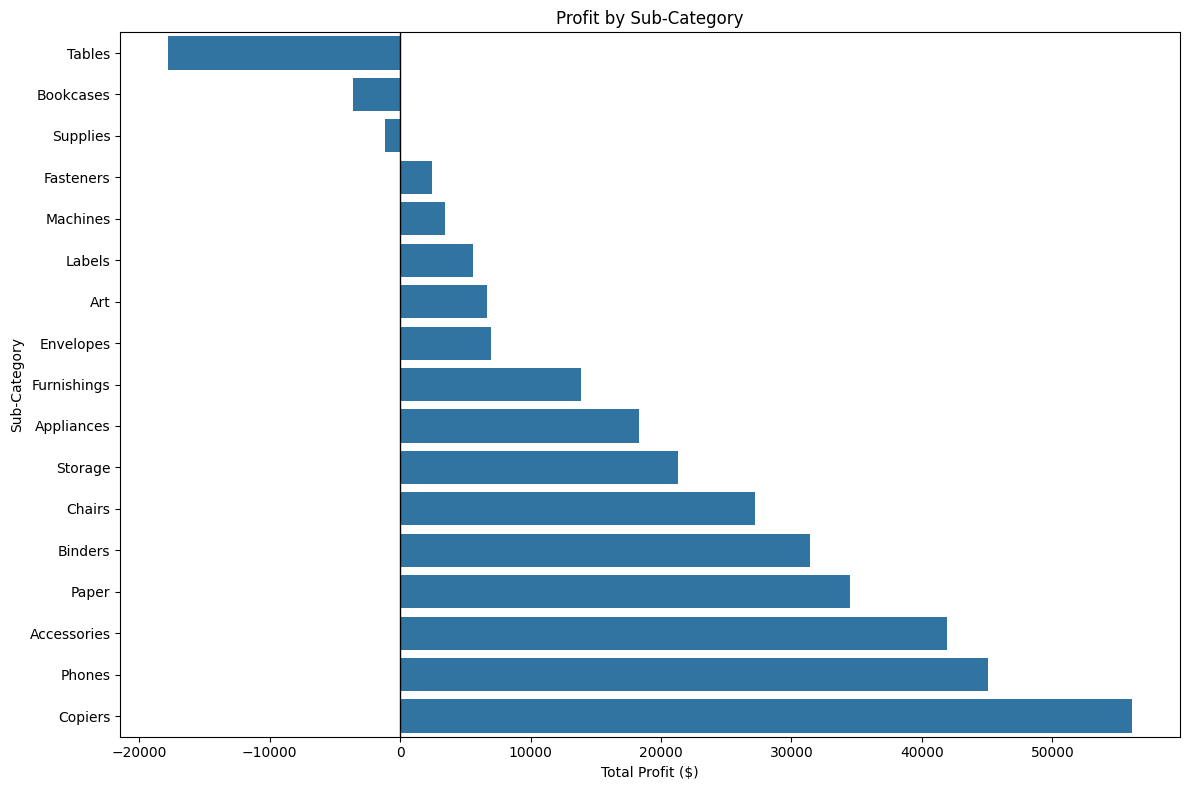

In [27]:
profit_sorted = subcategory_analysis.sort_values("Total_Profit")

plt.figure(figsize=(12, 8))

sns.barplot(
    data=profit_sorted,
    x="Total_Profit",
    y="Sub-Category"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Profit by Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

In [28]:
product_analysis = df.groupby(
    ["Product ID", "Product Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
).reset_index()

product_analysis["Profit_Margin_%"] = (
    product_analysis["Total_Profit"]
    / product_analysis["Total_Sales"] * 100
)

print("TOP 10 PRODUCTS BY PROFIT")
display(
    product_analysis.nlargest(10, "Total_Profit").round(2)
)

print("BOTTOM 10 PRODUCTS BY PROFIT")
display(
    product_analysis.nsmallest(10, "Total_Profit").round(2)
)

TOP 10 PRODUCTS BY PROFIT


,Product ID,Product Name,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20,40.91
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38,7753.04,31,28.24
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38,37.07
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,11619.83,4570.93,19,39.34
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,18374.90,4094.98,12,22.29
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95,11,49.00
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97,11,26.00
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,9367.29,3696.28,24,39.46
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,15875.92,3345.28,13,21.07
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,6965.70,3343.54,6,48.00


BOTTOM 10 PRODUCTS BY PROFIT


,Product ID,Product Name,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97,9,-80.00
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97,18,-27.27
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99,4,-48.00
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.64,-2876.12,27,-29.00
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,9544.72,-1934.40,33,-20.27
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27,-10.45
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08,6,-8.00
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,16656.20,-1299.18,22,-7.80
346,FUR-TA-10001950,Balt Solid Wood Round Tables,6518.75,-1201.06,19,-18.42
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,1706.25,-1148.44,15,-67.31


In [29]:
discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Transactions=("Order ID", "count")
).reset_index()

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"] * 100
)

display(discount_analysis.round(2))

,Discount,Total_Sales,Total_Profit,Total_Orders,Transactions,Profit_Margin_%
0,0.00,1105323.79,326718.59,2714,4925,29.56
1,0.10,54952.50,9099.97,91,96,16.56
2,0.15,27558.52,1418.99,51,52,5.15
3,0.20,773939.40,91079.95,2440,3706,11.77
4,0.30,104474.07,-10513.45,214,230,-10.06
5,0.32,14493.46,-2391.14,27,27,-16.50
6,0.40,116497.76,-23086.37,186,207,-19.82
7,0.45,5484.97,-2493.11,10,11,-45.45
8,0.50,58918.54,-20506.43,64,66,-34.80
9,0.60,7105.94,-6164.35,138,149,-86.75


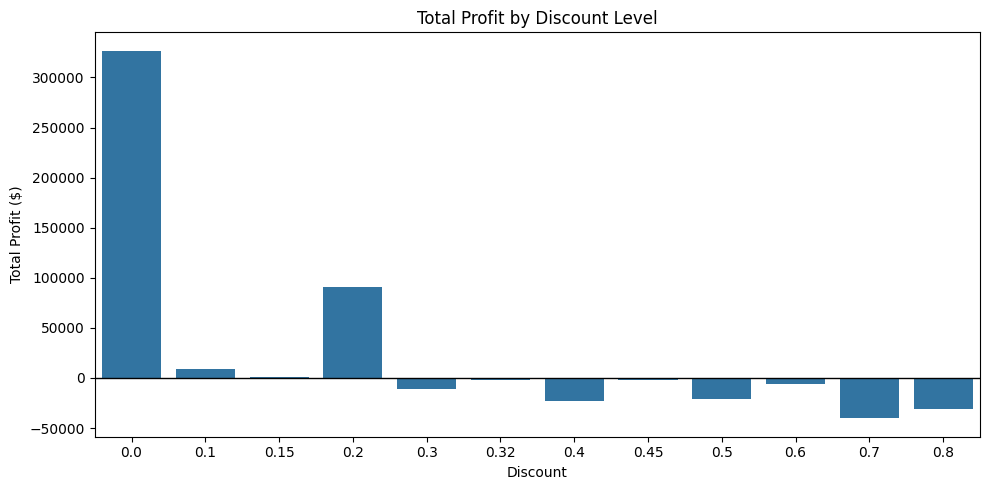

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis,
    x="Discount",
    y="Total_Profit"
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit ($)")
plt.tight_layout()
plt.show()

In [31]:
average_profit_by_discount = df.groupby("Discount").agg(
    Average_Sales=("Sales", "mean"),
    Average_Profit=("Profit", "mean"),
    Transaction_Count=("Profit", "size")
).reset_index()

display(average_profit_by_discount.round(2))

,Discount,Average_Sales,Average_Profit,Transaction_Count
0,0.00,224.43,66.34,4925
1,0.10,572.42,94.79,96
2,0.15,529.97,27.29,52
3,0.20,208.83,24.58,3706
4,0.30,454.24,-45.71,230
5,0.32,536.79,-88.56,27
6,0.40,562.79,-111.53,207
7,0.45,498.63,-226.65,11
8,0.50,892.71,-310.70,66
9,0.60,47.69,-41.37,149


In [32]:
tables_df = df[df["Sub-Category"] == "Tables"]

tables_discount_analysis = tables_df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Transaction_Count=("Profit", "size")
).reset_index()

display(tables_discount_analysis.round(2))

,Discount,Total_Sales,Total_Profit,Average_Profit,Transaction_Count
0,0.00,71706.23,13334.92,175.46,76
1,0.20,45636.58,-298.40,-4.14,72
2,0.30,25902.98,-3493.84,-62.39,56
3,0.40,45614.41,-16187.40,-215.83,75
4,0.45,5484.97,-2493.11,-226.65,11
5,0.50,13675.01,-8615.39,-239.32,36


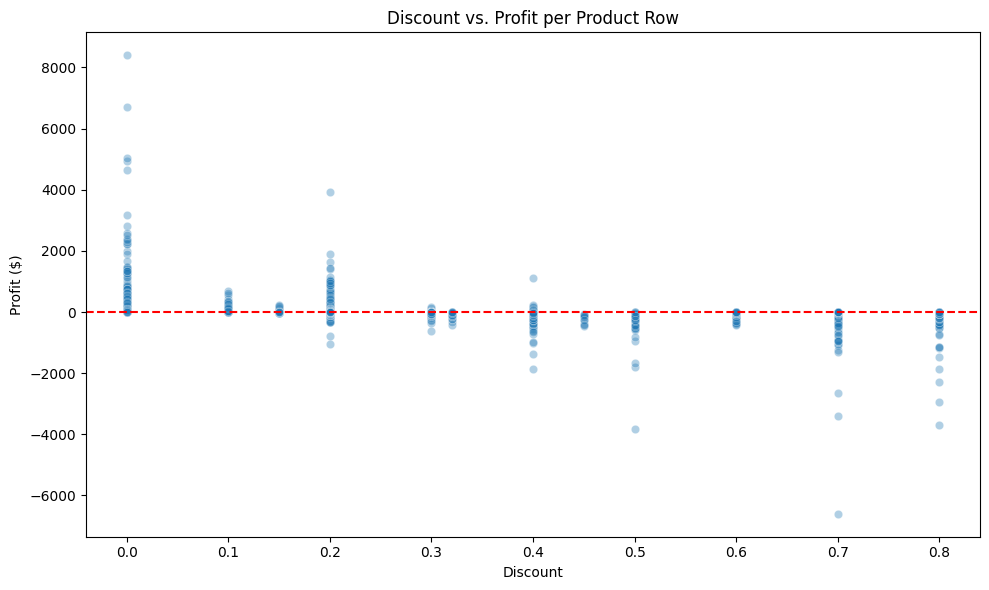

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.35
)

plt.axhline(0, color="red", linestyle="--")
plt.title("Discount vs. Profit per Product Row")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()

In [34]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Unique_Customers=("Customer ID", "nunique"),
    Total_Orders=("Order ID", "nunique"),
    Units_Sold=("Quantity", "sum")
).reset_index()

segment_analysis["Profit_Margin_%"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"] * 100
)

display(
    segment_analysis.sort_values(
        "Total_Sales", ascending=False
    ).round(2)
)

,Segment,Total_Sales,Total_Profit,Unique_Customers,Total_Orders,Units_Sold,Profit_Margin_%
0,Consumer,1170659.79,136371.45,416,2628,19844,11.65
1,Corporate,715806.13,94249.64,239,1552,11898,13.17
2,Home Office,440068.43,61675.73,149,931,6912,14.02


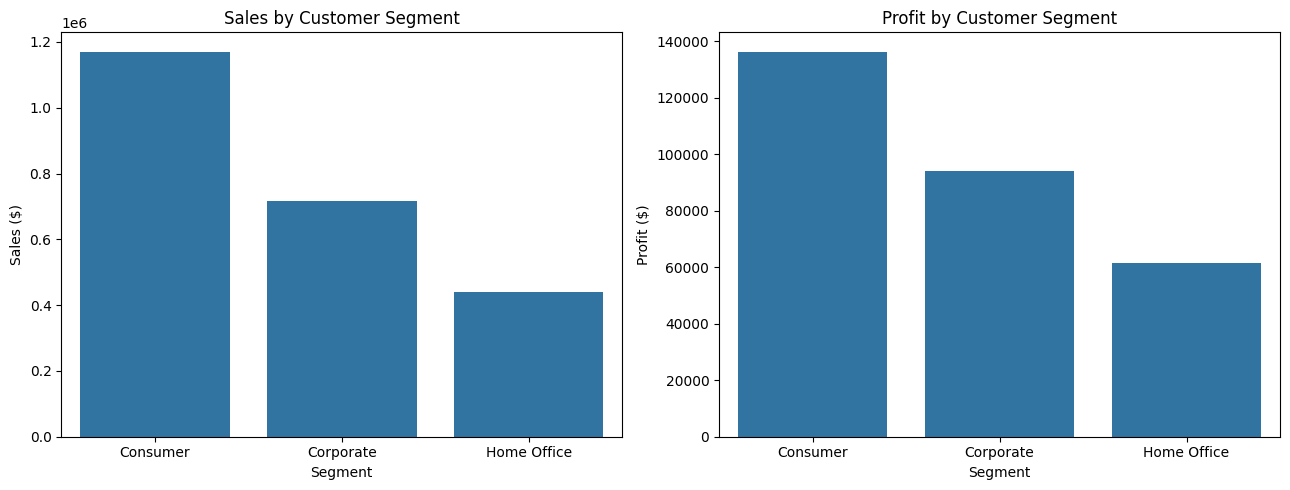

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Sales",
    ax=axes[0]
)
axes[0].set_title("Sales by Customer Segment")
axes[0].set_ylabel("Sales ($)")

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Profit",
    ax=axes[1]
)
axes[1].set_title("Profit by Customer Segment")
axes[1].set_ylabel("Profit ($)")

plt.tight_layout()
plt.show()

In [36]:
customer_analysis = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

print("TOP 10 CUSTOMERS BY PROFIT")

display(
    customer_analysis.nlargest(
        10, "Total_Profit"
    ).round(2)
)

TOP 10 CUSTOMERS BY PROFIT


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Orders
752,TC-20980,Tamara Chand,19052.22,8981.32,5
632,RB-19360,Raymond Buch,15117.34,6976.10,6
680,SC-20095,Sanjit Chand,14142.33,5757.41,9
328,HL-15040,Hunter Lopez,12873.30,5622.43,6
6,AB-10105,Adrian Barton,14473.57,5444.81,10
741,TA-21385,Tom Ashbrook,14595.62,4703.79,4
161,CM-12385,Christopher Martinez,8954.02,3899.89,4
433,KD-16495,Keith Dawkins,8181.26,3038.63,12
48,AR-10540,Andy Reiter,6608.45,2884.62,6
235,DR-12940,Daniel Raglin,8350.87,2869.08,8


In [37]:
print("BOTTOM 10 CUSTOMERS BY PROFIT")

display(
    customer_analysis.nsmallest(
        10, "Total_Profit"
    ).round(2)
)

BOTTOM 10 CUSTOMERS BY PROFIT


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Orders
181,CS-12505,Cindy Stewart,5690.06,-6626.39,6
311,GT-14635,Grant Thornton,9351.21,-4108.66,3
468,LF-17185,Luke Foster,3930.51,-3583.98,7
722,SR-20425,Sharelle Roach,3233.48,-3333.91,5
323,HG-14965,Henry Goldwyn,3247.64,-2797.96,12
565,NC-18415,Nathan Cano,2218.99,-2204.81,6
677,SB-20290,Sean Braxton,8057.89,-2082.75,7
711,SM-20320,Sean Miller,25043.05,-1980.74,5
166,CP-12340,Christine Phan,5888.28,-1850.30,8
571,NF-18385,Natalie Fritzler,8322.83,-1695.97,7


In [38]:
shipping_analysis = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Units_Sold=("Quantity", "sum")
).reset_index()

shipping_analysis["Profit_Margin_%"] = (
    shipping_analysis["Total_Profit"]
    / shipping_analysis["Total_Sales"] * 100
)

display(
    shipping_analysis.sort_values(
        "Total_Sales", ascending=False
    ).round(2)
)

,Ship Mode,Total_Sales,Total_Profit,Total_Orders,Units_Sold,Profit_Margin_%
3,Standard Class,1378840.55,168161.21,3068,23409,12.20
2,Second Class,466671.11,58962.13,982,7546,12.63
0,First Class,351750.74,49012.72,795,5724,13.93
1,Same Day,129271.96,16160.75,266,1975,12.50


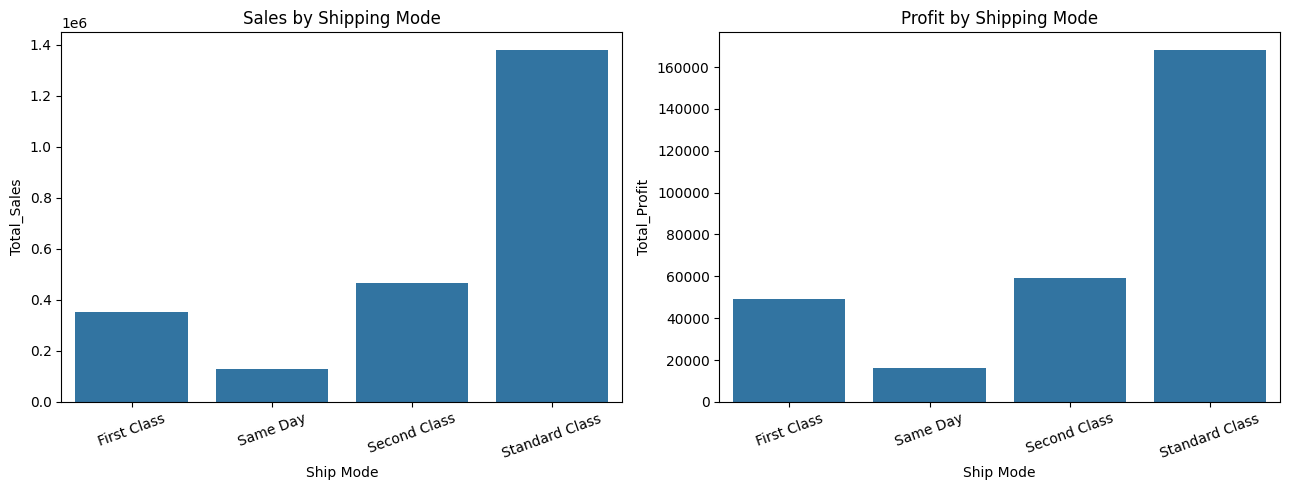

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=shipping_analysis,
    x="Ship Mode",
    y="Total_Sales",
    ax=axes[0]
)
axes[0].set_title("Sales by Shipping Mode")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=shipping_analysis,
    x="Ship Mode",
    y="Total_Profit",
    ax=axes[1]
)
axes[1].set_title("Profit by Shipping Mode")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [40]:
state_analysis = df.groupby("State/Province").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

state_analysis["Profit_Margin_%"] = (
    state_analysis["Total_Profit"]
    / state_analysis["Total_Sales"] * 100
)

print("TOP 10 STATES BY SALES")
display(
    state_analysis.nlargest(10, "Total_Sales").round(2)
)

print("BOTTOM 10 STATES BY PROFIT")
display(
    state_analysis.nsmallest(10, "Total_Profit").round(2)
)

TOP 10 STATES BY SALES


,State/Province,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
5,California,457687.63,76381.39,1021,16.69
34,New York,310876.27,74038.55,562,23.82
51,Texas,170188.05,-25729.36,487,-15.12
55,Washington,138641.27,33402.65,256,24.09
43,Pennsylvania,116511.91,-15559.96,288,-13.35
10,Florida,89473.71,-3399.30,200,-3.80
13,Illinois,80166.10,-12607.89,276,-15.73
39,Ohio,78258.14,-16971.38,236,-21.69
23,Michigan,76269.61,24463.19,117,32.07
54,Virginia,70636.72,18597.95,115,26.33


BOTTOM 10 STATES BY PROFIT


,State/Province,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
51,Texas,170188.05,-25729.36,487,-15.12
39,Ohio,78258.14,-16971.38,236,-21.69
43,Pennsylvania,116511.91,-15559.96,288,-13.35
13,Illinois,80166.10,-12607.89,276,-15.73
36,North Carolina,55603.16,-7490.91,136,-13.47
6,Colorado,32108.12,-6527.86,79,-20.33
50,Tennessee,30661.87,-5341.69,91,-17.42
2,Arizona,35282.00,-3427.92,108,-9.72
10,Florida,89473.71,-3399.30,200,-3.80
42,Oregon,17431.15,-1190.47,56,-6.83


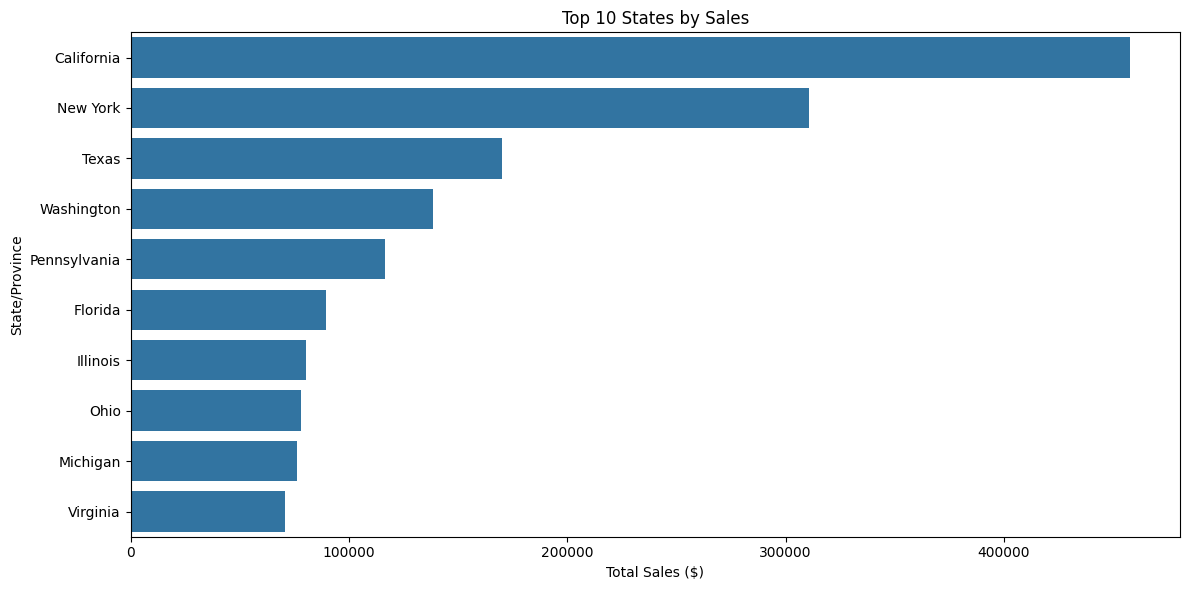

In [41]:
top_states = state_analysis.nlargest(10, "Total_Sales")

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_states,
    x="Total_Sales",
    y="State/Province"
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("State/Province")
plt.tight_layout()
plt.show()

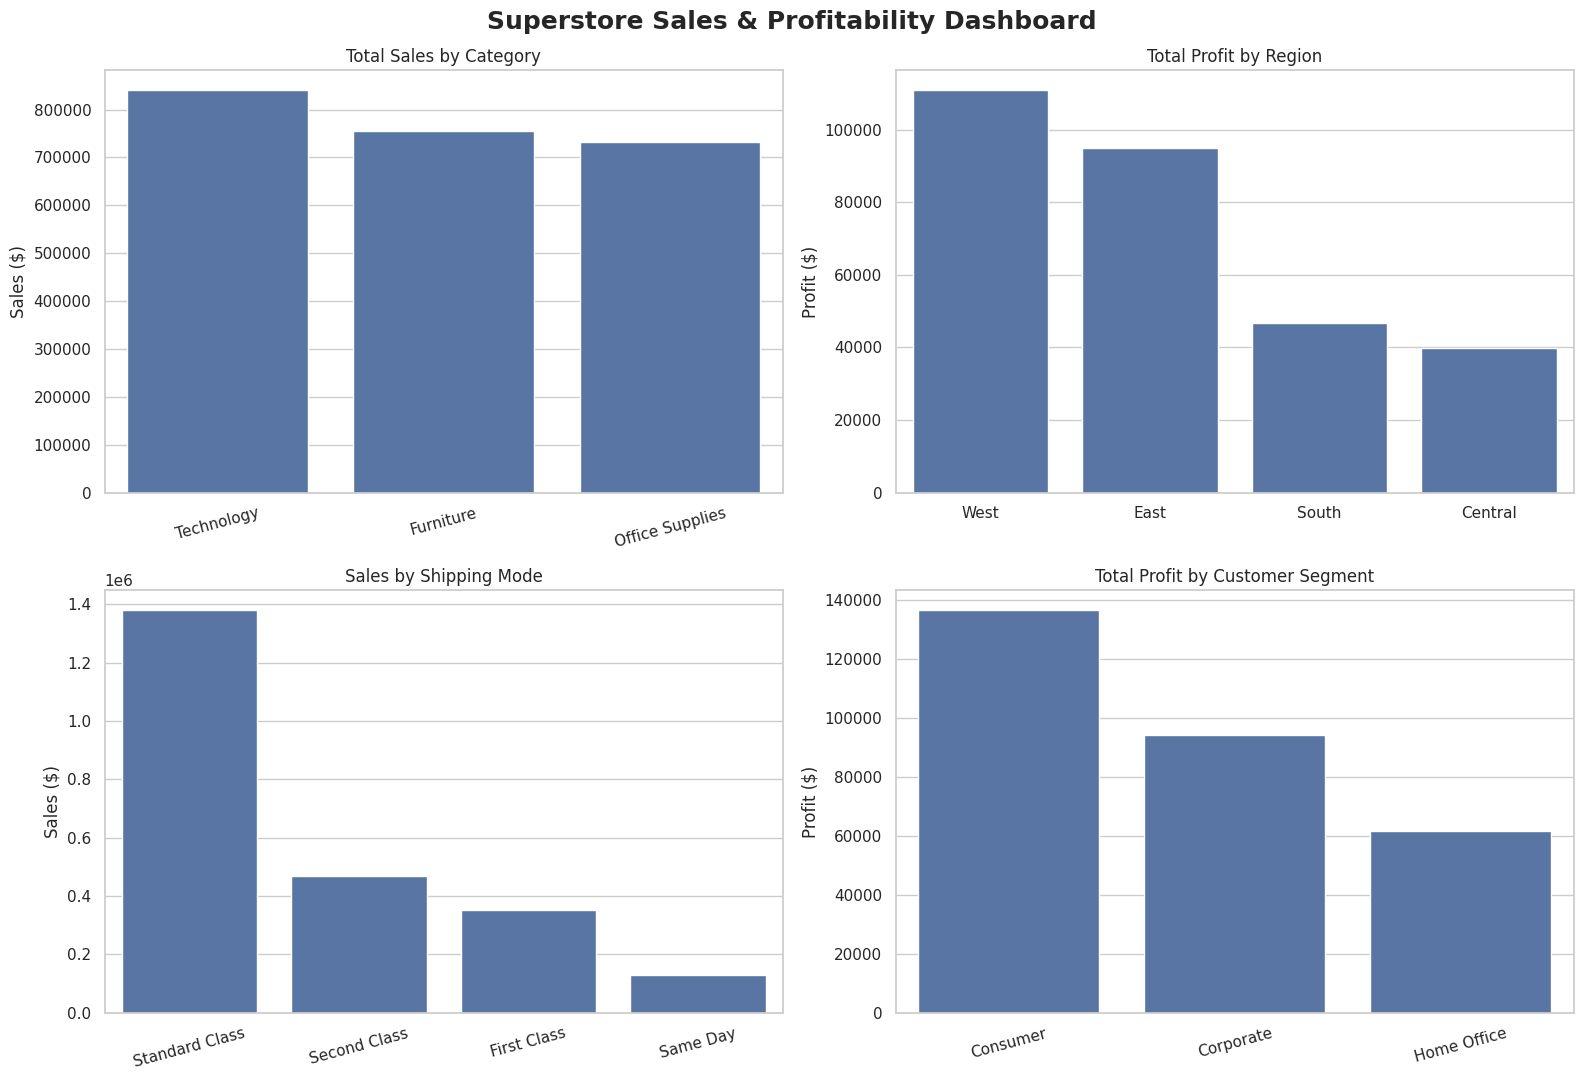

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Sales by category
category_plot = category_analysis.sort_values(
    "Total_Sales", ascending=False
)

sns.barplot(
    data=category_plot,
    x="Category",
    y="Total_Sales",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Total Sales by Category")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Sales ($)")
axes[0, 0].tick_params(axis="x", rotation=15)

# 2. Profit by region
region_plot = region_analysis.sort_values(
    "Total_Profit", ascending=False
)

sns.barplot(
    data=region_plot,
    x="Region",
    y="Total_Profit",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Total Profit by Region")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Profit ($)")

# 3. Sales by shipping mode
sns.barplot(
    data=shipping_analysis.sort_values(
        "Total_Sales", ascending=False
    ),
    x="Ship Mode",
    y="Total_Sales",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Sales by Shipping Mode")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Sales ($)")
axes[1, 0].tick_params(axis="x", rotation=15)

# 4. Profit by customer segment
sns.barplot(
    data=segment_analysis.sort_values(
        "Total_Profit", ascending=False
    ),
    x="Segment",
    y="Total_Profit",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Total Profit by Customer Segment")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Profit ($)")
axes[1, 1].tick_params(axis="x", rotation=15)

plt.suptitle(
    "Superstore Sales & Profitability Dashboard",
    fontsize=18,
    fontweight="bold"
)
plt.tight_layout()
plt.show()